# Blinkit Analytics: Data Cleaning and Exploratory Analysis

**Goal:** understand sales, delivery, customer feedback, marketing and inventory performance for a quick-commerce business, check how trustworthy the data is, and turn the findings into recommendations.

**Business questions**
1. How much revenue do we make, and which categories, segments and payment methods drive it?
2. How reliable is delivery, and what explains late orders?
3. Does delivery performance affect customer ratings?
4. Which marketing campaigns and channels give the best return?
5. Where are inventory losses highest?

**Note:** the dataset is synthetic (fake names, emails and phone numbers), so the results describe this dataset, not the real Blinkit business.

In [1]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"figure.figsize": (8, 4), "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
GREEN, YELLOW, RED = "#0C831F", "#F8CB46", "#D9473B"
RAW = Path("..") / "data" / "raw"
rd = lambda n: pd.read_csv(RAW / f"blinkit_{n}.csv")

orders, items, products = rd("orders"), rd("order_items"), rd("products")
customers, delivery, feedback = rd("customers"), rd("delivery_performance"), rd("customer_feedback")
marketing, inventory = rd("marketing_performance"), rd("inventory")
tables = {"orders": orders, "order_items": items, "products": products, "customers": customers,
          "delivery_performance": delivery, "customer_feedback": feedback, "marketing_performance": marketing, "inventory": inventory}
pd.DataFrame({n: {"rows": len(t), "columns": t.shape[1]} for n, t in tables.items()}).T

,rows,columns
orders,5000,10
order_items,5000,4
products,268,10
customers,2500,11
delivery_performance,5000,8
customer_feedback,5000,8
marketing_performance,5400,11
inventory,75172,4


## 1. Data quality checks

### 1.1 Missing values and duplicates

In [2]:
quality = pd.DataFrame({
    n: {"missing_cells": int(t.isna().sum().sum()), "duplicate_rows": int(t.duplicated().sum())}
    for n, t in tables.items()}).T
quality

,missing_cells,duplicate_rows
orders,0,0
order_items,0,0
products,0,0
customers,0,0
delivery_performance,1902,0
customer_feedback,0,0
marketing_performance,0,0
inventory,0,0


In [3]:
# the only column with missing values: reasons_if_delayed is blank for orders that were not delayed
print(delivery.isna().sum()[lambda s: s > 0])
print("Blank reason, on-time orders :", delivery.loc[delivery.delivery_status == "On Time", "reasons_if_delayed"].isna().all())
print("Reasons given for delays     :", delivery["reasons_if_delayed"].value_counts().to_dict())

reasons_if_delayed    1902
dtype: int64
Blank reason, on-time orders : False
Reasons given for delays     : {'Traffic': 3098}


The only missing values are blank delay reasons for on-time orders. That is expected, not an error. Every recorded delay reason is *Traffic*, so the column carries no information about why orders are late.

### 1.2 Keys and joins

In [4]:
checks = {
    "orders.order_id unique": orders.order_id.is_unique,
    "order_items.order_id unique (one item per order)": items.order_id.is_unique,
    "delivery.order_id unique": delivery.order_id.is_unique,
    "feedback.order_id unique": feedback.order_id.is_unique,
    "every order has an item": set(orders.order_id) <= set(items.order_id),
    "every item has a product": set(items.product_id) <= set(products.product_id),
    "every order has a customer": set(orders.customer_id) <= set(customers.customer_id),
}
pd.Series(checks, name="passes")

orders.order_id unique                              True
order_items.order_id unique (one item per order)    True
delivery.order_id unique                            True
feedback.order_id unique                            True
every order has an item                             True
every item has a product                            True
every order has a customer                          True
Name: passes, dtype: bool

All joins are safe: each order has exactly one item, one delivery record and one feedback row, so joining tables cannot duplicate revenue.

### 1.3 Does `order_total` match the items?

In [5]:
chk = orders.merge(items, on="order_id")
chk["items_value"] = chk.quantity * chk.unit_price
share = ((chk.order_total - chk.items_value).abs() < 1).mean()
print(f"Orders where order_total = quantity x unit_price: {share:.2%}")
print("Median order_total / items_value:", round((chk.order_total / chk.items_value).median(), 2))

Orders where order_total = quantity x unit_price: 0.14%
Median order_total / items_value: 2.4


**Finding:** `order_total` almost never equals `quantity x unit_price`. This is a limitation of the source data. All revenue figures in this project use `order_total` (the amount recorded for the order) and category figures use the single product on each order.

### 1.4 Date coverage and partial months

Orders from 2023-03-16 to 2024-11-04


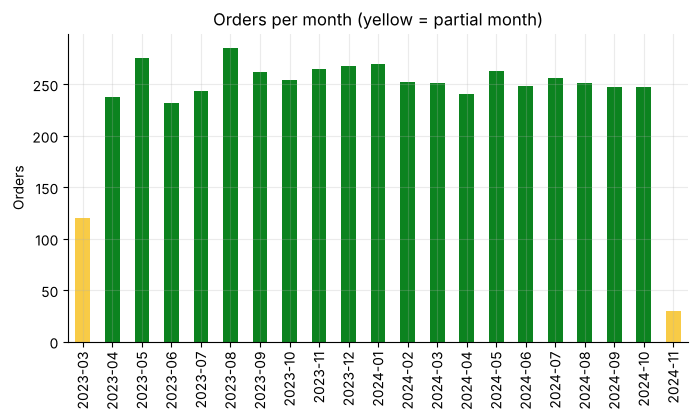

In [6]:
orders["order_date"] = pd.to_datetime(orders["order_date"])
print("Orders from", orders.order_date.min().date(), "to", orders.order_date.max().date())
monthly = orders.groupby(orders.order_date.dt.to_period("M")).size()
ax = monthly.plot(kind="bar", color=[YELLOW if m in (monthly.index[0], monthly.index[-1]) else GREEN for m in monthly.index])
ax.set_title("Orders per month (yellow = partial month)"); ax.set_xlabel(""); ax.set_ylabel("Orders"); plt.show()

March 2023 and November 2024 are partial months, since data starts on 16 March and ends on 4 November. Comparing them with full months would wrongly suggest sales collapsed, so they are flagged in every chart.

### 1.5 Delivery time and inventory sanity checks

In [7]:
print("delivery_time_minutes (minutes after promised time; negative = early):")
print(delivery.delivery_time_minutes.describe().round(1).to_string())
print()
inventory["date"] = pd.to_datetime(inventory["date"], format="%d-%m-%Y")
inventory["damaged_gt_received"] = inventory.damaged_stock > inventory.stock_received
print("Inventory rows:", len(inventory), "| damaged > received in", f"{inventory.damaged_gt_received.mean():.1%} of rows")
print("stock_received values:", sorted(map(int, inventory.stock_received.unique())), "| damaged_stock values:", sorted(map(int, inventory.damaged_stock.unique())))

delivery_time_minutes (minutes after promised time; negative = early):
count    5000.0
mean        4.4
std         8.1
min        -5.0
25%        -1.0
50%         2.0
75%         8.0
max        30.0

Inventory rows: 75172 | damaged > received in 38.9% of rows
stock_received values: [0, 1, 3, 4] | damaged_stock values: [0, 2]


**Finding:** `delivery_time_minutes` is really the delay against the promised time, not the delivery duration. In the inventory table, damaged units exceed received units in about 39% of rows, and `damaged_stock` only takes the values 0 or 2. Inventory damage rates are therefore **not reliable** and are reported with a warning.

**Cleaning decisions:** no rows were removed because there are no duplicates or invalid keys. Date columns were parsed (`order_date` ISO, inventory `dd-mm-yyyy`), partial months were flagged, and the unused `blinkit_inventoryNew.csv` was left out of the pipeline.

## 2. Build the analysis table

In [8]:
fact = (orders
        .merge(items, on="order_id")
        .merge(products[["product_id", "product_name", "category", "brand", "margin_percentage"]], on="product_id")
        .merge(customers[["customer_id", "customer_segment", "area"]], on="customer_id")
        .merge(delivery[["order_id", "delivery_time_minutes", "distance_km", "reasons_if_delayed"]], on="order_id")
        .merge(feedback[["order_id", "rating", "sentiment", "feedback_category"]], on="order_id"))
fact["month"] = fact.order_date.dt.to_period("M").astype(str)
fact["hour"] = fact.order_date.dt.hour
assert len(fact) == len(orders)
print(fact.shape)

(5000, 27)


## 3. Sales

In [9]:
rev, n = fact.order_total.sum(), len(fact)
pd.Series({"Orders": f"{n:,}", "Revenue": f"₹{rev:,.0f}", "Average order value": f"₹{fact.order_total.mean():,.0f}",
           "Median order value": f"₹{fact.order_total.median():,.0f}", "Average rating": round(fact.rating.mean(), 2),
           "On-time rate": f"{(fact.delivery_status == 'On Time').mean():.1%}"}, name="KPI").to_frame()

,KPI
Orders,"5,000"
Revenue,"₹11,009,308"
Average order value,"₹2,202"
Median order value,"₹2,101"
Average rating,3.34
On-time rate,69.4%


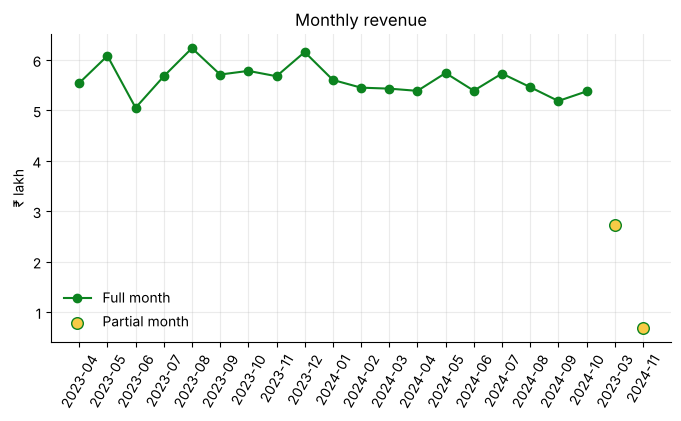

Full-month average: 5.61 lakh | range: 5.05 to 6.23


In [10]:
m = fact.groupby("month").order_total.sum() / 1e5
partial = ["2023-03", "2024-11"]
fig, ax = plt.subplots()
ax.plot(m.drop(partial).index, m.drop(partial).values, marker="o", color=GREEN, label="Full month")
ax.scatter(partial, m.loc[partial], s=70, color=YELLOW, edgecolor=GREEN, zorder=3, label="Partial month")
ax.set_title("Monthly revenue"); ax.set_ylabel("₹ lakh"); ax.legend(frameon=False); plt.xticks(rotation=60); plt.show()
print("Full-month average:", round(m.drop(partial).mean(), 2), "lakh | range:", round(m.drop(partial).min(), 2), "to", round(m.drop(partial).max(), 2))

Revenue is flat at about ₹5.6 lakh a month (₹5.1–6.2 lakh across full months), with no clear growth or seasonality. The two edge points are partial months.

,orders,revenue,aov,share_%
category,,,,
Dairy & Breakfast,566,1244369.0,2199.0,11.3
Household Care,509,1136440.0,2233.0,10.3
Pet Care,501,1125104.0,2246.0,10.2
Fruits & Vegetables,492,1085103.0,2205.0,9.9
Pharmacy,481,1055812.0,2195.0,9.6
Snacks & Munchies,483,1043582.0,2161.0,9.5
Grocery & Staples,449,1005495.0,2239.0,9.1
Personal Care,454,1003163.0,2210.0,9.1
Cold Drinks & Juices,375,828002.0,2208.0,7.5


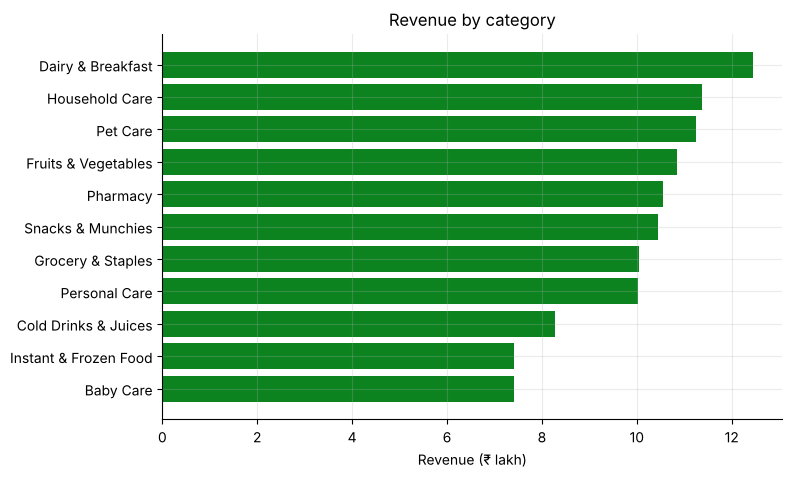

In [11]:
cat = fact.groupby("category").agg(orders=("order_id", "size"), revenue=("order_total", "sum"), aov=("order_total", "mean")).sort_values("revenue", ascending=False)
cat["share_%"] = (cat.revenue / cat.revenue.sum() * 100).round(1)
display(cat.round({"revenue": 0, "aov": 0, "share_%": 1}))
fig, ax = plt.subplots(figsize=(8, 5)); ax.barh(cat.index[::-1], cat.revenue[::-1] / 1e5, color=GREEN); ax.set_xlabel("Revenue (₹ lakh)"); ax.set_title("Revenue by category"); plt.show()

Dairy & Breakfast is the top category (11.3% of revenue). Average order value is similar across categories (roughly ₹2,080–2,250), so ranking differences come mainly from the **number of orders**, not from bigger baskets.

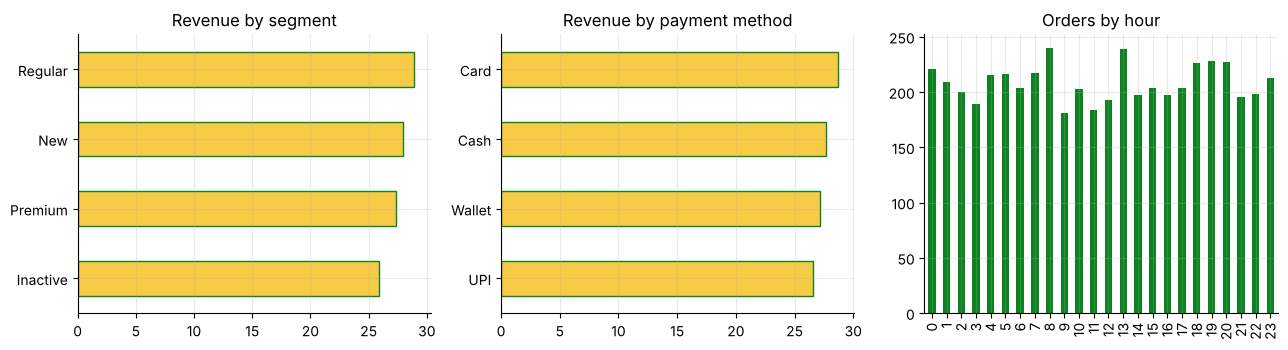

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col, t in zip(axes, ["customer_segment", "payment_method", "hour"], ["Revenue by segment", "Revenue by payment method", "Orders by hour"]):
    if col == "hour": fact.groupby("hour").size().plot(kind="bar", ax=ax, color=GREEN)
    else: (fact.groupby(col).order_total.sum() / 1e5).sort_values().plot(kind="barh", ax=ax, color=YELLOW, edgecolor=GREEN)
    ax.set_title(t); ax.set_ylabel(""); ax.set_xlabel("")
plt.tight_layout(); plt.show()

Segments and payment methods each contribute 23–27% of revenue, and orders are spread evenly through the day (no strong peak). Nothing here separates a clearly stronger group from the rest.

## 4. Delivery

delivery_status
On Time                  0.694
Slightly Delayed         0.207
Significantly Delayed    0.099

Average delay (min) by status:
delivery_status
On Time                   0.0
Significantly Delayed    22.8
Slightly Delayed         10.5


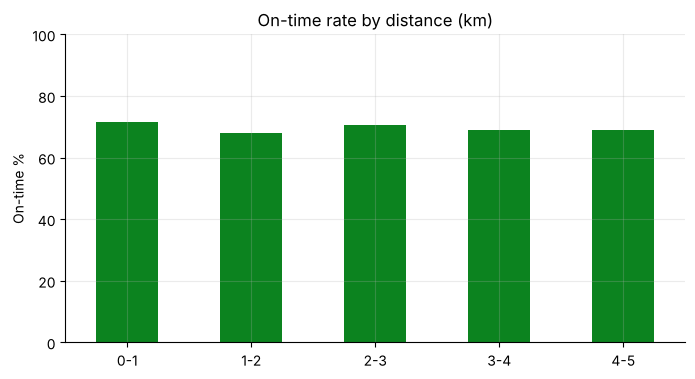

In [13]:
fact["late"] = fact.delivery_status != "On Time"
print(fact.delivery_status.value_counts(normalize=True).round(3).to_string())
print("\nAverage delay (min) by status:"); print(fact.groupby("delivery_status").delivery_time_minutes.mean().round(1).to_string())
fact["distance_band"] = pd.cut(fact.distance_km, [0, 1, 2, 3, 4, 5], labels=["0-1", "1-2", "2-3", "3-4", "4-5"])
ot = fact.groupby("distance_band", observed=True).apply(lambda d: (~d.late).mean() * 100)
ax = ot.plot(kind="bar", color=GREEN, ylim=(0, 100)); ax.set_title("On-time rate by distance (km)"); ax.set_ylabel("On-time %"); ax.set_xlabel(""); plt.xticks(rotation=0); plt.show()

In [14]:
chi2, p, *_ = stats.chi2_contingency(pd.crosstab(fact.distance_band, fact.late))
print(f"Distance vs late delivery: chi-square p = {p:.3f}")

Distance vs late delivery: chi-square p = 0.516


About 69% of orders are on time. On-time rate does not change with distance (p > 0.05), so distance does not explain late orders in this dataset.

## 5. Customer feedback

In [15]:
print("Average rating:", round(fact.rating.mean(), 2)); print(fact.sentiment.value_counts(normalize=True).round(3).to_string())
print("\nAverage rating by delivery status:"); print(fact.groupby("delivery_status").rating.mean().round(2).to_string())
groups = [g.rating.values for _, g in fact.groupby("delivery_status")]
h, p = stats.kruskal(*groups); print(f"\nRating differs by delivery status? Kruskal-Wallis p = {p:.3f}")

Average rating: 3.34
sentiment
Neutral     0.348
Negative    0.328
Positive    0.324

Average rating by delivery status:
delivery_status
On Time                  3.33
Significantly Delayed    3.33
Slightly Delayed         3.39

Rating differs by delivery status? Kruskal-Wallis p = 0.549


Customers who received late orders rate them the same as on-time ones (3.33 vs 3.33, not significant). In real data we would expect lateness to hurt ratings, so this suggests the ratings in this dataset were generated independently of delivery. It's worth stating as a limitation rather than a business insight.

## 6. Marketing

,spend,revenue,roas,conv_rate_%
campaign_name,,,,
Referral Program,1818026.0,3691383.0,2.03,10.2
App Push Notification,1788989.0,3554370.0,1.99,10.1
Email Campaign,1810730.0,3601785.0,1.99,9.6
Weekend Special,1799611.0,3571452.0,1.98,10.3
New User Discount,1833455.0,3603860.0,1.97,10.2
Membership Drive,1790070.0,3524951.0,1.97,9.7
Festival Offer,1796687.0,3507064.0,1.95,10.1
Flash Sale,1831688.0,3556087.0,1.94,10.0
Category Promotion,1850583.0,3582455.0,1.94,10.2


,spend,revenue,roas,conv_rate_%
channel,,,,
Email,3997488.0,8189332.0,2.05,9.9
SMS,3998608.0,7938649.0,1.99,9.8
Social Media,4110364.0,7990416.0,1.94,10.1
App,4213379.0,8075010.0,1.92,10.2


Overall ROAS 1.97x | CTR 10.1% | conversion 10.0%


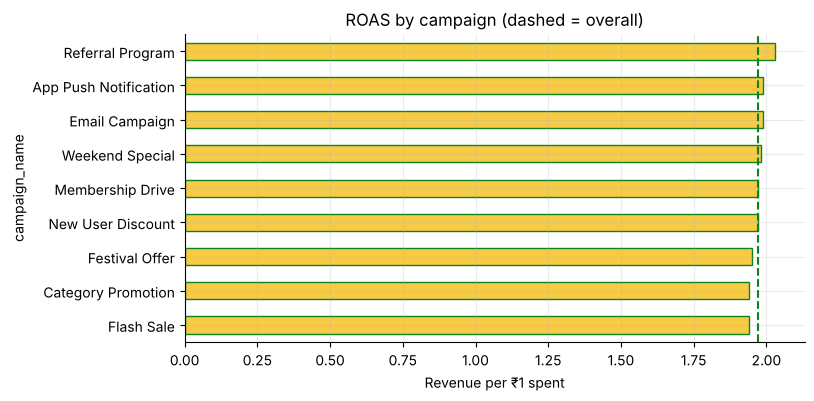

In [16]:
def roas_table(col):
    t = marketing.groupby(col).agg(spend=("spend", "sum"), revenue=("revenue_generated", "sum"), clicks=("clicks", "sum"), conversions=("conversions", "sum"))
    t["roas"] = (t.revenue / t.spend).round(2); t["conv_rate_%"] = (t.conversions / t.clicks * 100).round(1)
    return t.sort_values("roas", ascending=False)
camp, chan = roas_table("campaign_name"), roas_table("channel")
fmt = {"spend": 0, "revenue": 0, "roas": 2, "conv_rate_%": 1}
display(camp[list(fmt)].round(fmt)); display(chan[list(fmt)].round(fmt))
print(f"Overall ROAS {marketing.revenue_generated.sum() / marketing.spend.sum():.2f}x | CTR {marketing.clicks.sum() / marketing.impressions.sum():.1%} | conversion {marketing.conversions.sum() / marketing.clicks.sum():.1%}")
ax = camp.roas.sort_values().plot(kind="barh", color=YELLOW, edgecolor=GREEN); ax.axvline(1.97, color=GREEN, ls="--"); ax.set_title("ROAS by campaign (dashed = overall)"); ax.set_xlabel("Revenue per ₹1 spent"); plt.show()

Every campaign earns about ₹1.94–2.03 per ₹1 spent, so the spread is small: **Referral Program** is best, **Flash Sale** and **Category Promotion** weakest (both 1.94x); **Email** is the best channel. The marketing table's revenue (₹3.22 Cr) is about 3x total order revenue (₹1.10 Cr), so the two tables come from different sources and cannot be reconciled. Marketing results should be analysed on their own.

## 7. Inventory

,received,damaged,damage_rate_%
category,,,
Household Care,12034,8210,68.2
Personal Care,12239,7524,61.5
Dairy & Breakfast,14873,8890,59.8
Cold Drinks & Juices,11107,6604,59.5
Fruits & Vegetables,13670,8120,59.4
Snacks & Munchies,13845,8144,58.8
Instant & Frozen Food,10183,5910,58.0
Baby Care,9700,4828,49.8
Grocery & Staples,15036,7144,47.5


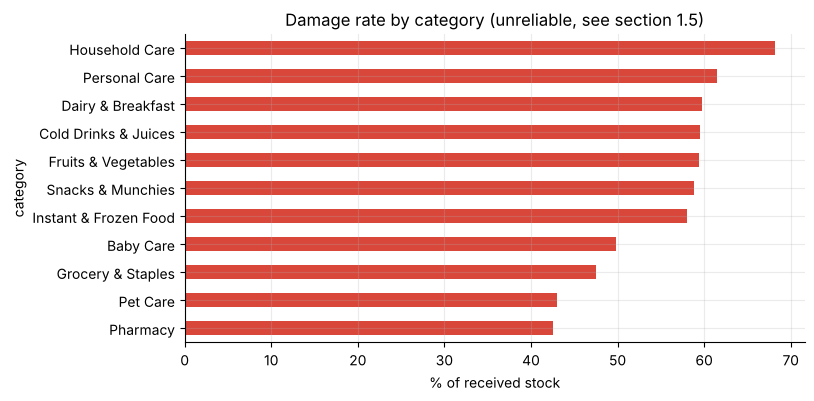

In [17]:
inv = inventory.merge(products[["product_id", "category"]], on="product_id")
d = inv.groupby("category").agg(received=("stock_received", "sum"), damaged=("damaged_stock", "sum"))
d["damage_rate_%"] = (d.damaged / d.received * 100).round(1); d = d.sort_values("damage_rate_%", ascending=False); display(d)
ax = d["damage_rate_%"][::-1].plot(kind="barh", color=RED); ax.set_title("Damage rate by category (unreliable, see section 1.5)"); ax.set_xlabel("% of received stock"); plt.show()

Household Care and Personal Care show the highest damage rates, but with damaged units above received units in 39% of rows, these figures should be validated before anyone acts on them.

## 8. Conclusions and recommendations

| # | Finding | Recommendation |
|---|---|---|
| 1 | Revenue is steady (~₹5.6 L/month) with no growth trend; the two edge months are partial. | Investigate growth levers; always flag incomplete months in reporting. |
| 2 | Dairy & Breakfast leads; Baby Care and Instant & Frozen Food trail. Differences come from order count, not basket size. | Promote low-volume categories to raise order frequency rather than basket value. |
| 3 | 30.6% of orders are late, with "Traffic" the only recorded reason, and distance does not explain it. | Record richer delay reasons (rider, store prep, weather); review rider allocation and promised-time estimates. |
| 4 | ROAS is ~1.97x across the board; Referral Program (2.03x) and Email (2.05x) lead slightly. | Test shifting a share of budget to Referral and Email, and run A/B tests, since the gaps are small. |
| 5 | Inventory damage looks implausible (39% of rows have damaged > received). | Fix the stock-damage data capture first, then reanalyse. |

**Limitations:** synthetic data; `order_total` does not reconcile with items; marketing and order revenue come from unreconciled sources; ratings are independent of delivery; one item per order; no costs, so no profit analysis.

**Next steps:** forecast monthly orders, model late-delivery risk once richer features exist, and add profit analysis using `margin_percentage`.